# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Identitas Mahasiswa**
- Nama  : Regia Shafna Rimba
- NIM   : 241011400318
- Kelas : Reg C

> `RANDOM_STATE` sementara diisi **22**. Ganti angka itu jika 2 digit terakhir NIM bukan 22, lalu jalankan ulang notebook supaya angka evaluasi ikut berubah.


## Ketentuan yang dipakai
Model dan metrik dibuat sendiri dengan NumPy (disalin dari materi `simple_regression` dan `simple_classification`). Library yang dipakai: `numpy`, `pandas`, `matplotlib`. `scikit-learn` hanya pada soal bonus.


In [1]:
# import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 2 digit terakhir NIM. Jika 00, pakai 100.
RANDOM_STATE = 22


ModuleNotFoundError: No module named 'numpy'

In [ ]:
# train_test_split dari materi: acak indeks, lalu potong sesuai test_size
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


# Normal equation: beta = (X_b^T X_b)^{-1} X_b^T y
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_


# Gradient descent. loss_history_ menyimpan MSE tiap iterasi.
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient
            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_


class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


def mae(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

# confusion_matrix: [[TN, FP], [FN, TP]]
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) else 0.0


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Dataset: `Ads_Data.csv`.


### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv`, tampilkan 5 data pertama serta jumlah baris.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). `X` berbentuk `(n, 1)`.
3. Scatter plot `BiayaIklan` vs `Penjualan`.


5 data pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris: 40
Shape X: (40, 1) | Shape y: (40,)


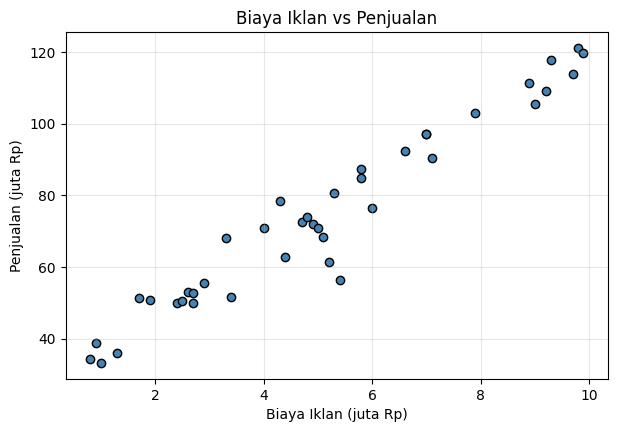

In [ ]:
# Jawaban A1
ads = pd.read_csv('Ads_Data.csv')
print('5 data pertama:')
display(ads.head())
print('Jumlah baris:', len(ads))

X = ads[['BiayaIklan']].values
y = ads['Penjualan'].values
print('Shape X:', X.shape, '| Shape y:', y.shape)

plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, c='steelblue', edgecolors='k')
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, alpha=0.3)
plt.show()


### Soal A2 – Split Data
`test_size=0.2`, `random_state=RANDOM_STATE`.


In [ ]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation


In [ ]:
# Jawaban A3
regressor = LinearRegression()
regressor.fit(X_train, y_train)

b = regressor.intercept_
m = regressor.coefficients_[0]
print(f'Intercept (b)  = {b:.6f}')
print(f'Koefisien (m)  = {m:.6f}')
print(f'Persamaan: y_hat = {b:.3f} + {m:.3f} * BiayaIklan')


Intercept (b)  = 28.491887
Koefisien (m)  = 9.098640
Persamaan: y_hat = 28.492 + 9.099 * BiayaIklan


**Jawaban A3 (interpretasi):**

Intercept $b \approx 28{,}492$ dan koefisien $m \approx 9{,}099$, sehingga garis regresinya

$$\hat{y} = 28{,}492 + 9{,}099X$$

dengan $X$ = biaya iklan (juta Rp) dan $\hat{y}$ = penjualan (juta Rp).

Nilai $m$ berarti setiap kenaikan biaya iklan sebesar **1 juta Rp**, penjualan diperkirakan naik sekitar **9,10 juta Rp**, selama hubungan yang diamati tetap linier. Intercept 28,49 juta Rp adalah penjualan taksiran saat biaya iklan = 0. Angka itu hanya titik potong garis, bukan hasil yang diamati, karena data terkecil biaya iklannya 0,8 juta Rp.


### Soal A4 – Evaluasi Model


In [ ]:
# Jawaban A4
def eval_regresi(model, X_data, y_data):
    pred = model.predict(X_data)
    return {
        'MAE': mae(y_data, pred),
        'MSE': mse(y_data, pred),
        'RMSE': rmse(y_data, pred),
        'R2': r2_score(y_data, pred),
    }

tabel_a4 = pd.DataFrame({
    'Training': eval_regresi(regressor, X_train, y_train),
    'Testing': eval_regresi(regressor, X_test, y_test),
}).T
tabel_a4


,MAE,MSE,RMSE,R2
Training,4.230049,32.937932,5.739158,0.941534
Testing,5.541355,48.623982,6.973090,0.943068


**Jawaban A4 (analisis):**

Pada data testing, RMSE $\approx 6{,}97$ juta Rp dan $R^2 \approx 0{,}943$. RMSE adalah akar rata-rata kuadrat selisih prediksi dan penjualan asli, dalam satuan yang sama dengan penjualan. Artinya kesalahan tipikal model di data yang tidak ikut dilatih kira-kira 7 juta Rp. Rentang penjualan di dataset adalah 33,2 sampai 121,1 juta Rp, jadi kesalahan sebesar itu relatif kecil.

$R^2 \approx 0{,}94$ berarti sekitar 94% variasi penjualan pada data testing bisa dijelaskan oleh biaya iklan. $R^2$ training ($0{,}942$) dan testing ($0{,}943$) hampir sama, jadi model tidak menghafal data training. Model ini sudah baik untuk hubungan linier biaya iklan dan penjualan pada rentang data yang ada.


### Soal A5 – Gradient Descent & Learning Rate
Tiga learning rate: `0.001`, `0.02`, dan `0.1`, masing-masing `n_iterations=5000`.


In [ ]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
hasil_gd = []
model_gd = {}

for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    model_gd[lr] = gd
    hasil_gd.append({
        'learning_rate': lr,
        'intercept': gd.intercept_,
        'koefisien': gd.coefficients_[0],
        'loss_terakhir_finite': np.array(gd.loss_history_)[np.isfinite(gd.loss_history_)][-1],
    })

print('Normal equation -> b =', b, ' m =', m)
pd.DataFrame(hasil_gd)


Normal equation -> b = 28.491887249410485  m = 9.098640000121943


C:\Users\22-Regina Shafna\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\22-Regina Shafna\AppData\Local\Temp\ipykernel_35508\1017940413.py:71: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b @ beta) ** 2)
C:\Users\22-Regina Shafna\AppData\Local\Temp\ipykernel_35508\1017940413.py:69: RuntimeWarning: overflow encountered in matmul
  gradient = X_b.T @ (y_hat - y) / len(y)
C:\Users\22-Regina Shafna\AppData\Local\Temp\ipykernel_35508\1017940413.py:70: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient


,learning_rate,intercept,koefisien,loss_terakhir_finite
0,0.001,19.270717,10.606261,5.123670e+01
1,0.020,28.491887,9.098640,3.293793e+01
2,0.100,NaN,NaN,2.048628e+306


C:\Users\22-Regina Shafna\AppData\Local\Programs\Python\Python311\Lib\site-packages\matplotlib\scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


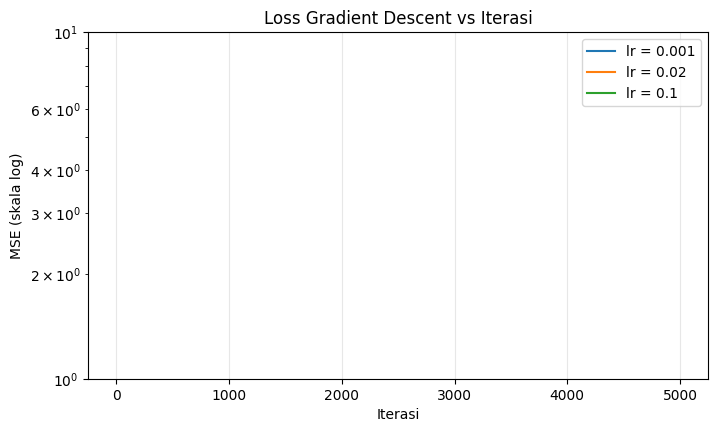

In [ ]:
plt.figure(figsize=(8, 4.5))
for lr in learning_rates:
    loss = np.asarray(model_gd[lr].loss_history_, dtype=float)
    finite = np.isfinite(loss)
    # lr yang divergen hanya digambar sampai nilainya masih finite
    plt.plot(np.arange(1, finite.sum() + 1), loss[finite], label=f'lr = {lr}')

plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('MSE (skala log)')
plt.title('Loss Gradient Descent vs Iterasi')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Jawaban A5 (analisis):**

Learning rate **0.001 terlalu lambat**. Setelah 5000 iterasi, intercept-nya masih sekitar 19,27 dan koefisien sekitar 10,61, belum menyamai normal equation ($b \approx 28{,}49$, $m \approx 9{,}10$). Loss akhir masih sekitar 51, di atas MSE optimal training sekitar 32,94. Langkahnya terlalu kecil, jadi 5000 iterasi belum sampai ke dasar lembah loss.

Learning rate **0.02 pas**. Intercept dan koefisien-nya sama dengan normal equation sampai beberapa angka di belakang koma (28,492 dan 9,099), dan loss akhirnya tepat di MSE training. Kurva loss turun cepat lalu mendatar.

Learning rate **0.1 gagal konvergen (divergen)**. Loss naik tajam lalu menjadi `inf`/`nan`, dan muncul `RuntimeWarning: overflow`. Update $\beta = \beta - \alpha \nabla$ terlalu besar dibanding lengkungan loss, sehingga tiap langkah meloncat melewati minimum dan error makin membesar sampai melebihi batas angka floating point. Pada data ini skala penjualan (puluhan–ratusan) membuat gradien besar; 0,1 sudah melewati batas learning rate yang stabil, sedangkan 0,02 masih di bawah batas itu.


### Soal A6 – Visualisasi & Prediksi


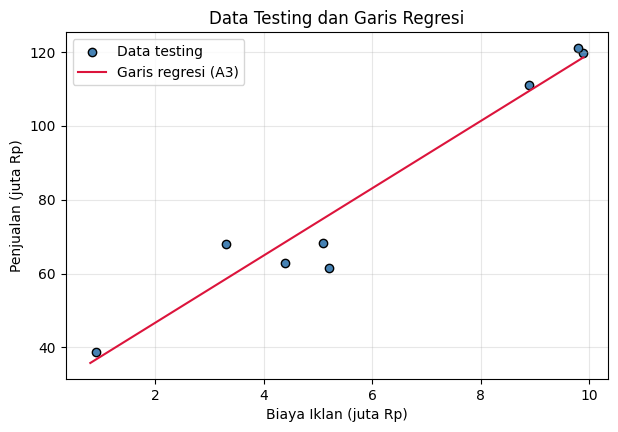

Rentang BiayaIklan pada data: 0.8 sampai 9.9


,BiayaIklan (juta Rp),Prediksi Penjualan (juta Rp)
0,4.5,69.435767
1,7.0,92.182367
2,12.0,137.675567


In [ ]:
# Jawaban A6
y_test_pred = regressor.predict(X_test)

plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, c='steelblue', edgecolors='k', label='Data testing')
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(x_line, regressor.predict(x_line), c='crimson', label='Garis regresi (A3)')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = regressor.predict(biaya_baru)
tabel_pred = pd.DataFrame({
    'BiayaIklan (juta Rp)': biaya_baru.ravel(),
    'Prediksi Penjualan (juta Rp)': pred_baru,
})
print('Rentang BiayaIklan pada data:', X.min(), 'sampai', X.max())
tabel_pred


**Jawaban A6 (analisis):**

Prediksi penjualan: biaya iklan 4,5 juta Rp $\rightarrow$ sekitar **69,4 juta Rp**; 7 juta Rp $\rightarrow$ sekitar **92,2 juta Rp**; 12 juta Rp $\rightarrow$ sekitar **137,7 juta Rp**.

Dua angka pertama masih masuk akal karena 4,5 dan 7 berada di dalam rentang data (0,8 sampai 9,9 juta Rp) dan titik-titik testing mengikuti garis regresi. Prediksi 12 juta **kurang bisa dipercaya**. Nilai itu ekstrapolasi: tidak ada bulan dengan biaya iklan 12 juta di data, dan hubungan linier tidak dijamin berlanjut. Dalam iklan, tambahan anggaran sering memberi kenaikan penjualan yang makin kecil (diminishing return), atau malah mentok pada kapasitas toko. Angka 137,7 juta Rp hanya sah jika asumsi "setiap +1 juta iklan selalu +9,1 juta penjualan" masih berlaku di luar data, dan asumsi itu tidak teruji.


---
# Bagian B – Logistic Regression (40%)

Filter spam sederhana dari `JumlahLink` dan `KataPromo`. Dataset: `Email_Data.csv`.


### Soal B1 – Load & Visualisasi Data


5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris: 60
Spam
Bukan Spam (0)    35
Spam (1)          25
Name: count, dtype: int64


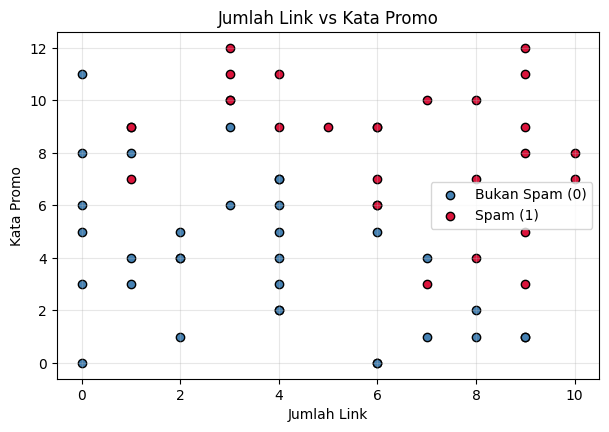

In [ ]:
# Jawaban B1
email = pd.read_csv('Email_Data.csv')
print('5 data pertama:')
display(email.head())
print('Jumlah baris:', len(email))
print(email['Spam'].value_counts().rename({0: 'Bukan Spam (0)', 1: 'Spam (1)'}))

X_email = email[['JumlahLink', 'KataPromo']].values
y_email = email['Spam'].values

plt.figure(figsize=(7, 4.5))
bukan = y_email == 0
spam = y_email == 1
plt.scatter(X_email[bukan, 0], X_email[bukan, 1], c='steelblue', edgecolors='k', label='Bukan Spam (0)')
plt.scatter(X_email[spam, 0], X_email[spam, 1], c='crimson', edgecolors='k', label='Spam (1)')
plt.title('Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Soal B2 – Split Data & Training
`test_size=0.25`, `learning_rate=0.1`, `n_iterations=10000`.


X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)


Intercept (b) = -8.792223
m1 (JumlahLink) = 0.756944
m2 (KataPromo)  = 0.763654
P(Spam) = sigmoid(-8.792 + 0.757*JumlahLink + 0.764*KataPromo)


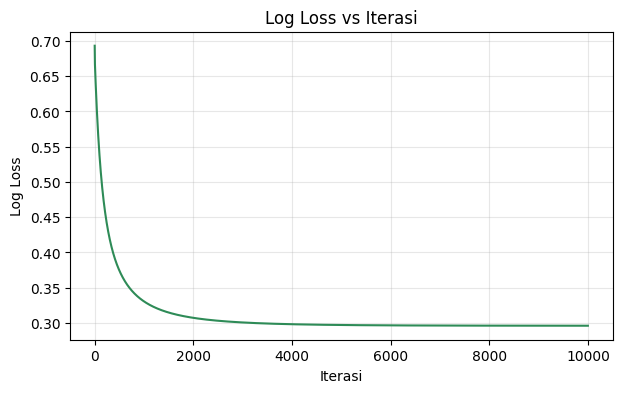

Loss awal : 0.6931471805599452
Loss akhir: 0.2960721437199588


In [ ]:
# Jawaban B2
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print('X_train:', Xe_train.shape, '| X_test:', Xe_test.shape)
print('y_train:', ye_train.shape, '| y_test:', ye_test.shape)

classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(Xe_train, ye_train)

b_log = classifier.intercept_
m1, m2 = classifier.coefficients_
print(f'Intercept (b) = {b_log:.6f}')
print(f'm1 (JumlahLink) = {m1:.6f}')
print(f'm2 (KataPromo)  = {m2:.6f}')
print(f'P(Spam) = sigmoid({b_log:.3f} + {m1:.3f}*JumlahLink + {m2:.3f}*KataPromo)')

plt.figure(figsize=(7, 4))
plt.plot(classifier.loss_history_, c='seagreen')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.title('Log Loss vs Iterasi')
plt.grid(True, alpha=0.3)
plt.show()

print('Loss awal :', classifier.loss_history_[0])
print('Loss akhir:', classifier.loss_history_[-1])


**Jawaban B2 (analisis):**

Persamaan model:

$$P(\text{Spam}) = \sigma(-8{,}792 + 0{,}757 \cdot \text{JumlahLink} + 0{,}764 \cdot \text{KataPromo})$$

Kedua koefisien positif: makin banyak link dan makin banyak kata promo, peluang spam makin besar. Log loss mulai dari sekitar 0,693 (setara tebakan 50:50) lalu turun dan mendatar di sekitar 0,296. Penurunan di iterasi akhir sudah kecil, jadi training sudah stabil dan tidak divergen. Model layak dipakai untuk klasifikasi, dengan catatan threshold default 0,5 masih akan dicek di soal B5.


### Soal B3 – Evaluasi Model


In [ ]:
# Jawaban B3 — threshold default 0.5, diukur pada data testing
ye_pred = classifier.predict(Xe_test)
cm = confusion_matrix(ye_test, ye_pred)
tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]

print('Accuracy :', accuracy_score(ye_test, ye_pred))
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(cm)
print('Precision:', precision_score(ye_test, ye_pred))
print('Recall   :', recall_score(ye_test, ye_pred))
print('F1-score :', f1_score(ye_test, ye_pred))
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')


Accuracy : 0.9333333333333333
Confusion matrix [[TN, FP], [FN, TP]]:
[[9 1]
 [0 5]]
Precision: 0.8333333333333334
Recall   : 1.0
F1-score : 0.9090909090909091
TN=9, FP=1, FN=0, TP=5


**Jawaban B3 (analisis):**

Pada data testing (15 email) akurasinya $14/15 \approx 0{,}933$. Confusion matrix-nya $\begin{bmatrix} 9 & 1 \\ 0 & 5 \end{bmatrix}$: 9 bukan-spam benar (TN), 1 bukan-spam dikira spam (FP), 0 spam yang lolos (FN), dan 5 spam yang tertangkap (TP). Precision $\approx 0{,}833$, recall $= 1{,}0$, F1 $\approx 0{,}909$.

**FP** pada filter spam adalah email biasa yang masuk folder spam. Pengguna bisa tidak melihat tagihan, email dosen, atau pesan kerja. **FN** adalah spam yang lolos ke kotak masuk: mengganggu, tetapi email asli tetap sampai.

Menurut saya **FP lebih merugikan**. Email penting yang terkubur di spam sering tidak dibaca sama sekali, sedangkan spam yang lolos masih bisa dihapus. Karena itu model sebaiknya tidak terlalu mudah menandai email sebagai spam. Pilihan threshold yang mengikuti pendapat ini ada di soal B5.


### Soal B4 – Decision Boundary


Decision boundary: KataPromo = -(b + m1*JumlahLink) / m2
x2 = -(-8.792 + 0.757*x1) / 0.764


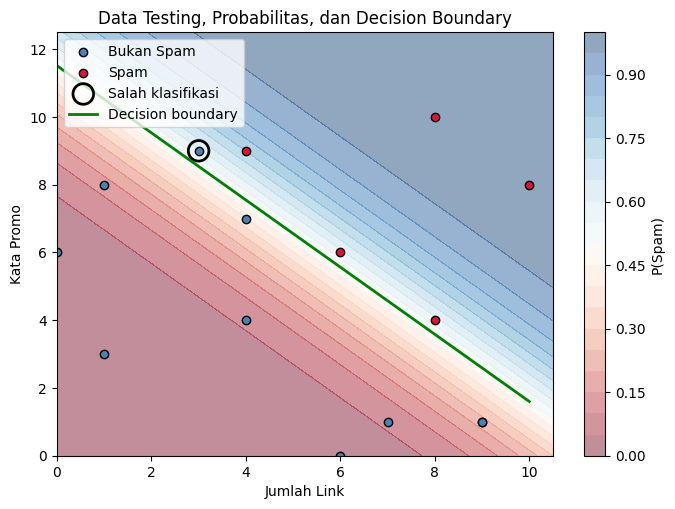

Data testing yang salah:
   JumlahLink  KataPromo  Label asli  Prediksi  P(Spam)
0           3          9           0         1    0.587


In [ ]:
# Jawaban B4
# saat P=0.5, z=0, jadi KataPromo = -(b + m1*JumlahLink) / m2
x1_line = np.linspace(0, 10, 100)
x2_line = -(b_log + m1 * x1_line) / m2
print('Decision boundary: KataPromo = -(b + m1*JumlahLink) / m2')
print(f'x2 = -({b_log:.3f} + {m1:.3f}*x1) / {m2:.3f}')

x1_grid, x2_grid = np.meshgrid(np.linspace(0, 10.5, 200), np.linspace(0, 12.5, 200))
grid = np.c_[x1_grid.ravel(), x2_grid.ravel()]
proba_grid = classifier.predict_proba(grid).reshape(x1_grid.shape)

salah = ye_pred != ye_test

plt.figure(figsize=(8, 5.5))
plt.contourf(x1_grid, x2_grid, proba_grid, levels=20, cmap='RdBu', alpha=0.45)
plt.colorbar(label='P(Spam)')
plt.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], c='steelblue', edgecolors='k', label='Bukan Spam')
plt.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], c='crimson', edgecolors='k', label='Spam')
plt.scatter(
    Xe_test[salah, 0], Xe_test[salah, 1],
    facecolors='none', edgecolors='black', s=220, linewidths=2, marker='o',
    label='Salah klasifikasi',
)
plt.plot(x1_line, x2_line, c='green', lw=2, label='Decision boundary')
plt.xlim(0, 10.5)
plt.ylim(0, 12.5)
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.title('Data Testing, Probabilitas, dan Decision Boundary')
plt.legend(loc='upper left')
plt.show()

print('Data testing yang salah:')
print(pd.DataFrame({
    'JumlahLink': Xe_test[salah, 0],
    'KataPromo': Xe_test[salah, 1],
    'Label asli': ye_test[salah],
    'Prediksi': ye_pred[salah],
    'P(Spam)': classifier.predict_proba(Xe_test[salah]).round(3),
}))


**Jawaban B4 (analisis):**

Garis decision boundary (peluang spam = 0,5) adalah

$$\text{KataPromo} = -\frac{-8{,}792 + 0{,}757 \cdot \text{JumlahLink}}{0{,}764}$$

Warna latar makin merah berarti peluang spam makin tinggi. Hanya **satu** data testing yang salah: `JumlahLink = 3`, `KataPromo = 9`, label asli bukan spam, tetapi diprediksi spam karena $P(\text{Spam}) \approx 0{,}587$. Titik itu dekat garis batas. Kata promonya banyak, jadi model condong ke spam meskipun link-nya sedikit. Tidak ada spam yang lolos di sisi biru (FN = 0 pada threshold 0,5).


### Soal B5 – Eksperimen Threshold


In [ ]:
# Jawaban B5
baris = []
for threshold in [0.3, 0.5, 0.7]:
    pred_t = classifier.predict(Xe_test, threshold=threshold)
    cm_t = confusion_matrix(ye_test, pred_t)
    baris.append({
        'threshold': threshold,
        'TN': cm_t[0, 0],
        'FP': cm_t[0, 1],
        'FN': cm_t[1, 0],
        'TP': cm_t[1, 1],
        'precision': precision_score(ye_test, pred_t),
        'recall': recall_score(ye_test, pred_t),
        'f1': f1_score(ye_test, pred_t),
    })

tabel_b5 = pd.DataFrame(baris)
THRESHOLD = 0.7  # pilihan dari analisis B3: FP lebih merugikan
tabel_b5


,threshold,TN,FP,FN,TP,precision,recall,f1
0,0.3,8,2,0,5,0.714286,1.0,0.833333
1,0.5,9,1,0,5,0.833333,1.0,0.909091
2,0.7,10,0,2,3,1.000000,0.6,0.750000


**Jawaban B5 (analisis):**

Menaikkan threshold membuat model hanya menyebut spam jika peluangnya tinggi. Akibatnya **FP turun dan precision naik**, tetapi sebagian spam yang peluangnya sedang tidak tertangkap, jadi **FN naik dan recall turun**. Menurunkan threshold adalah kebalikannya: recall naik (lebih banyak spam tertangkap) tetapi precision turun karena email biasa ikut tertandai.

Di tabel ini, threshold 0,3 punya FP = 2 dan precision $\approx 0{,}71$; threshold 0,5 punya FP = 1 dan precision $\approx 0{,}83$ dengan recall = 1; threshold 0,7 punya FP = 0 dan precision = 1, tetapi recall turun menjadi 0,6 (dua spam lolos).

Saya memilih **threshold 0,7**. Di soal B3, FP lebih merugikan karena email penting bisa tidak terbaca. Threshold 0,7 menghilangkan FP pada data testing ini. Harganya dua spam lolos ke kotak masuk, dan itu masih bisa dihapus manual. F1 tertinggi memang di 0,5, tetapi pilihan ini mengikuti prioritas "jangan salah buang email asli", bukan F1 semata.


### Soal B6 – Prediksi Email Baru
Threshold yang dipakai: **0,7**.


In [ ]:
# Jawaban B6
email_baru = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11],
])
proba_baru = classifier.predict_proba(email_baru)
kelas_baru = classifier.predict(email_baru, threshold=THRESHOLD)

tabel_b6 = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': email_baru[:, 0],
    'KataPromo': email_baru[:, 1],
    'P(Spam)': proba_baru.round(4),
    'Prediksi': np.where(kelas_baru == 1, 'Spam', 'Bukan Spam'),
})
print('Threshold:', THRESHOLD)
tabel_b6


Threshold: 0.7


,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0015,Bukan Spam
1,E2,5,6,0.3952,Bukan Spam
2,E3,9,10,0.9965,Spam
3,E4,2,11,0.7543,Spam


---
# Bagian C – Pemahaman Konsep (15%)


**Jawaban C1:**

Logistic Regression tetap disebut regression karena yang dihitung lebih dulu adalah kombinasi linier $z = b + m_1 x_1 + m_2 x_2$, sama seperti regresi. Bedanya, keluaran yang dipakai bukan $z$, melainkan kelas. Fungsi sigmoid mengubah $z$ menjadi peluang antara 0 dan 1. Peluang itu lalu dibandingkan dengan threshold (biasanya 0,5) sehingga hasil akhirnya adalah kategori, misalnya spam atau bukan spam, bukan angka penjualan. Karena itu algoritmanya dipakai untuk klasifikasi.

**Jawaban C2:**

Normal equation menghitung koefisien dalam satu langkah lewat rumus $\beta = (X_b^T X_b)^{-1} X_b^T y$. Gradient descent memulai $\beta$ dari nol lalu menggesernya sedikit demi sedikit mengikuti arah penurunan loss, sebanyak `n_iterations`. Normal equation praktis kalau data tidak terlalu besar dan $X_b^T X_b$ bisa dibalik, seperti 32 baris training pada Bagian A. Gradient descent lebih masuk akal kalau baris data sangat banyak (membalik matriks mahal), atau kalau loss tidak punya solusi tertutup. Logistic regression ada di kasus kedua, jadi di materi ia dilatih dengan gradient descent.

**Jawaban C3:**

Data training sudah dilihat model saat koefisien dicari, jadi error di situ cenderung terlalu kecil dan tidak menggambarkan email atau bulan iklan yang baru. Data testing tidak ikut menentukan $b$ dan $m$, jadi metrik di situ lebih jujur tentang kemampuan model di data baru. Overfitting terjadi ketika model terlalu menempel pada data training, termasuk noise-nya, sehingga skor training bagus tetapi skor testing jatuh. Pada regresi iklan, $R^2$ training dan testing sama-sama sekitar 0,94, jadi tanda overfitting itu tidak muncul.

**Jawaban C4:**

Linear regression mengeluarkan angka kontinu (penjualan dalam juta Rp). MSE menghukum selisih $y - \hat{y}$ dalam satuan yang sama dan gradiennya sederhana, jadi cocok sebagai loss. Logistic regression mengeluarkan peluang antara 0 dan 1 untuk kejadian Bernoulli (spam / bukan). Log loss adalah negatif log-likelihood peluang itu: kalau model sangat yakin tetapi salah (peluang mendekati 0 padahal labelnya 1), hukumannya besar. MSE pada peluang tidak menghukum kesalahan yang terlalu percaya diri sekuat log loss, dan juga bukan turunan dari model peluang sigmoid.

**Jawaban C5:**

Soal meminta `random_state` sama dengan dua digit terakhir NIM, dan `train_test_split` memakai angka itu untuk mengacak baris sebelum dipotong. NIM yang berbeda menghasilkan subset training dan testing yang berbeda, sehingga koefisien, RMSE, $R^2$, dan akurasi ikut berbeda walaupun dataset dan rumusnya sama. Learning rate dan jumlah iterasi yang sama pun tidak meniadakan perbedaan itu, karena gradient descent melihat data training yang tidak identik.


---
# Bonus (+5) – Perbandingan dengan scikit-learn

Model dilatih ulang pada **data training yang sama**. Linear regression sklearn memakai normal equation (tanpa penalti). Logistic regression sklearn secara default memakai penalti L2 (`C=1`). Sebagai pembanding, saya juga melatih sklearn logistic dengan `C` sangat besar supaya penaltinya hampir hilang.


In [ ]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

sk_reg = SklearnLinearRegression()
sk_reg.fit(X_train, y_train)
sk_pred = sk_reg.predict(X_test)

print('--- Linear Regression ---')
print('NumPy  b, m :', regressor.intercept_, regressor.coefficients_)
print('sklearn b, m:', sk_reg.intercept_, sk_reg.coef_)
print('R2 test NumPy  :', r2_score(y_test, regressor.predict(X_test)))
print('R2 test sklearn:', r2_score(y_test, sk_pred))
print('RMSE test NumPy  :', rmse(y_test, regressor.predict(X_test)))
print('RMSE test sklearn:', rmse(y_test, sk_pred))

# default sklearn: L2, C=1. C besar ≈ hampir tanpa penalti.
sk_clf = SklearnLogisticRegression(C=1.0, solver='lbfgs', max_iter=10000)
sk_clf.fit(Xe_train, ye_train)
sk_clf_weak = SklearnLogisticRegression(C=1e12, solver='lbfgs', max_iter=10000)
sk_clf_weak.fit(Xe_train, ye_train)

print('--- Logistic Regression ---')
print('NumPy          b, m:', classifier.intercept_, classifier.coefficients_)
print('sklearn C=1    b, m:', sk_clf.intercept_[0], sk_clf.coef_[0])
print('sklearn C=1e12 b, m:', sk_clf_weak.intercept_[0], sk_clf_weak.coef_[0])
print('Acc test NumPy      :', accuracy_score(ye_test, classifier.predict(Xe_test)))
print('Acc test sklearn C=1:', accuracy_score(ye_test, sk_clf.predict(Xe_test)))
print('Acc test sklearn weak:', accuracy_score(ye_test, sk_clf_weak.predict(Xe_test)))


--- Linear Regression ---
NumPy  b, m : 28.491887249410485 [9.09864]
sklearn b, m: 28.491887249410546 [9.09864]
R2 test NumPy  : 0.9430680864216806
R2 test sklearn: 0.9430680864216806
RMSE test NumPy  : 6.973089828735835
RMSE test sklearn: 6.973089828735839
--- Logistic Regression ---
NumPy          b, m: -8.792223005965209 [0.75694416 0.76365371]
sklearn C=1    b, m: -8.171717558202152 [0.69865447 0.71118495]
sklearn C=1e12 b, m: -8.961857364398579 [0.77168358 0.77782063]
Acc test NumPy      : 0.9333333333333333
Acc test sklearn C=1: 0.9333333333333333
Acc test sklearn weak: 0.9333333333333333


**Jawaban Bonus (analisis):**

Linear regression NumPy dan `sklearn.linear_model.LinearRegression` menghasilkan intercept, koefisien, RMSE, dan $R^2$ yang sama. Keduanya menyelesaikan normal equation pada data training yang sama, jadi tidak ada perbedaan yang berarti.

Logistic regression berbeda, terutama pada koefisien. Implementasi NumPy tidak memakai penalti: yang diminimalkan hanya log loss. `LogisticRegression` scikit-learn secara default memakai penalti **L2** dengan `C=1`. Penalti itu menarik koefisien ke arah nol, sehingga intercept sklearn tidak negatif-nya lebih kecil dan kedua slope-nya lebih kecil daripada hasil NumPy. Parameter `C` adalah kebalikan kekuatan penalti: `C` kecil berarti penalti kuat, `C` besar berarti penalti lemah. Saat `C=1e12`, koefisien sklearn bergerak mendekati model tanpa penalti, meskipun tidak identik dengan NumPy karena sklearn memakai solver `lbfgs` sampai konvergen, sedangkan NumPy memakai gradient descent dengan learning rate 0,1 dan tepat 10000 iterasi. Akurasi testing kebetulan sama (0,933) karena perbedaan koefisien belum cukup untuk memindahkan prediksi threshold 0,5 pada 15 data uji ini.
